Code for Analysis 3: 

--> Connectome Analysis for Generated Figures

In [1]:
# import necessary libraries
import random
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from collections import Counter
import pickle

# file configurations
INPUT_DIR = Path("inputs")
REGULON_FILES = {                      
    "TF Link":   "../data/TFLink_Caenorhabditis_elegans_interactions_All_GMT_proteinName_v1.0.gmt",
}
SEED = 0
TYPES = ["sensory", "interneuron", "motor", "pharyngeal"]
OUT = Path("../figures/analysis1")
XS = [5, 10, 25, 50, 100, 250, 500, 1000, 2000]   # top-X DE genes per neuron (sensitivity analysis)
N_PERM = 100                           # edge-swap permutations
OUT.mkdir(exist_ok=True)

In [2]:
# data load

meta = pd.read_csv(INPUT_DIR / "neurons.csv")
counts = pd.read_csv(INPUT_DIR / "counts.csv", index_col=0)
meta["neuron"] = meta["neuron"].astype(str)
nodes = [n for n in meta["neuron"] if n in counts.columns]
meta = meta.set_index("neuron").loc[nodes]
types = meta["type"]
counts = counts[nodes]
counts = counts.loc[counts.sum(axis=1) > 0]
print(f"{len(nodes)} neurons, {counts.shape[0]} genes")
print(types.value_counts().to_dict())    

path = Path("inputs") / "nets.pkl"  
with path.open("rb") as file:
    nets = pickle.load(file)

path = Path("inputs") / "conn.pkl"  
with path.open("rb") as file:
    conn = pickle.load(file)

edges = pd.read_csv(INPUT_DIR / "edges.csv")
print(f"connectome (undirected projection): {conn.number_of_edges()} edges")

# gene sources for expression networks: all genes, plus each regulon collection
sources, reg_sets = {"All Genes": None}, {}
reg_files = {nm: read_gene_sets(p) for nm, p in REGULON_FILES.items()}
for name, sets in reg_files.items():
    sources[f"Neural Regulon TFs"] = set().union(*sets.values())
    reg_sets.update({f"{name}:{k}": v for k, v in sets.items()})
if len(reg_files) > 1:
    sources["regulon_combined"] = set().union(*reg_sets.values())
print("gene sources:", list(sources))

126 neurons, 13546 genes
{'interneuron': 45, 'sensory': 39, 'motor': 28, 'pharyngeal': 14}
connectome (undirected projection): 1474 edges


NameError: name 'read_gene_sets' is not defined

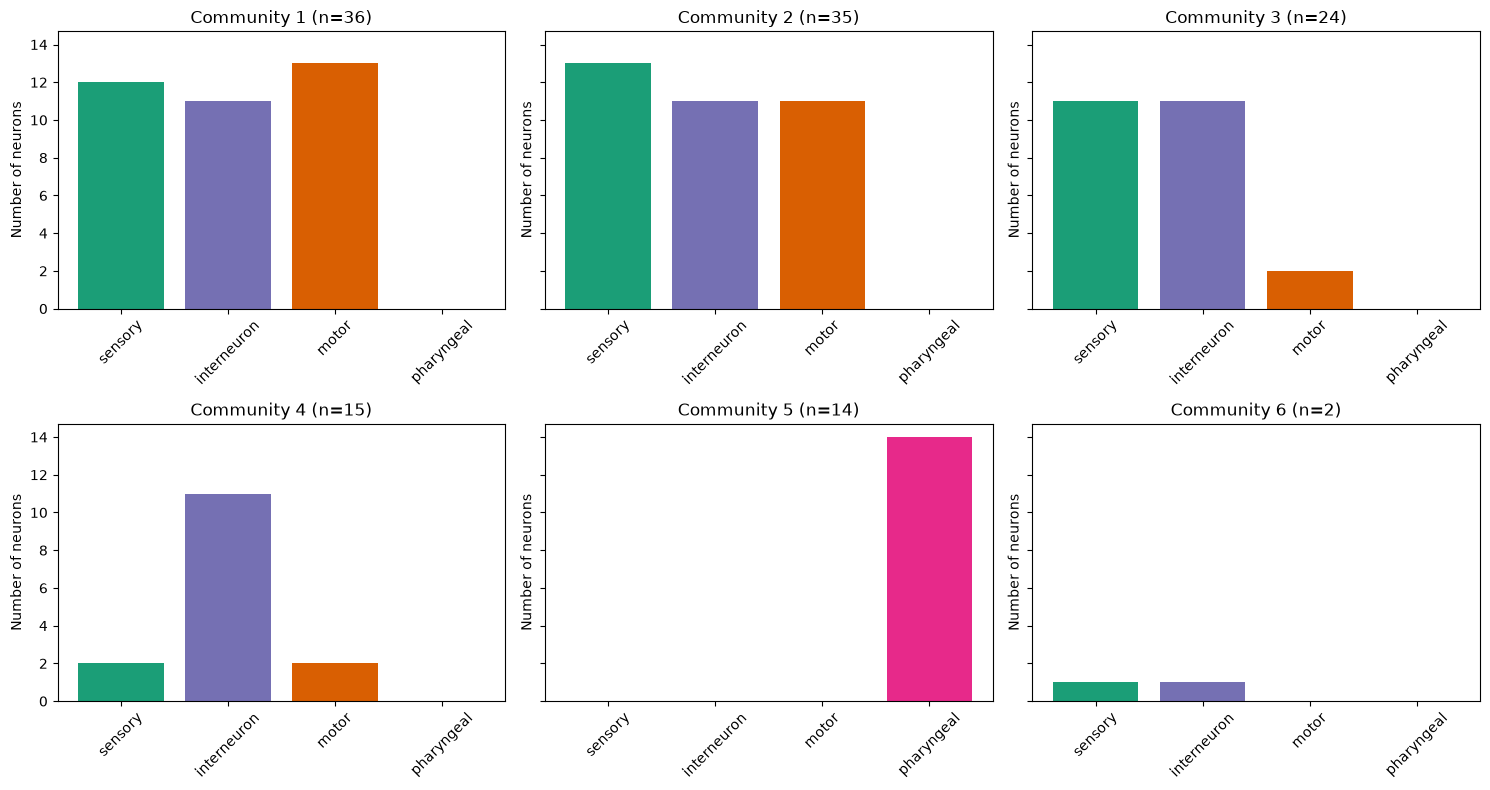

Connectome: 6 Greedy Modularity communities
  All Genes: X with 6 communities -> [250, 500, 1000]
  Neural Regulon TFs: X with 6 communities -> [100, 500]


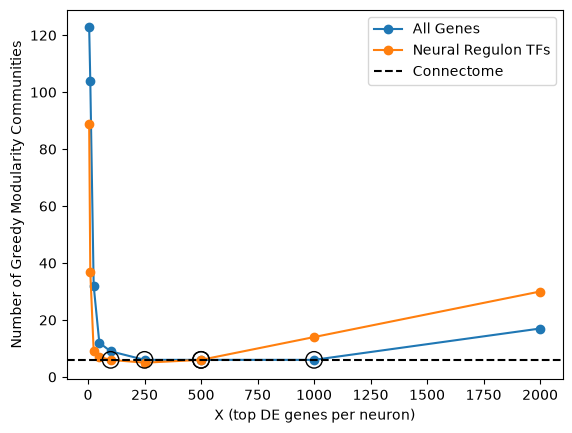

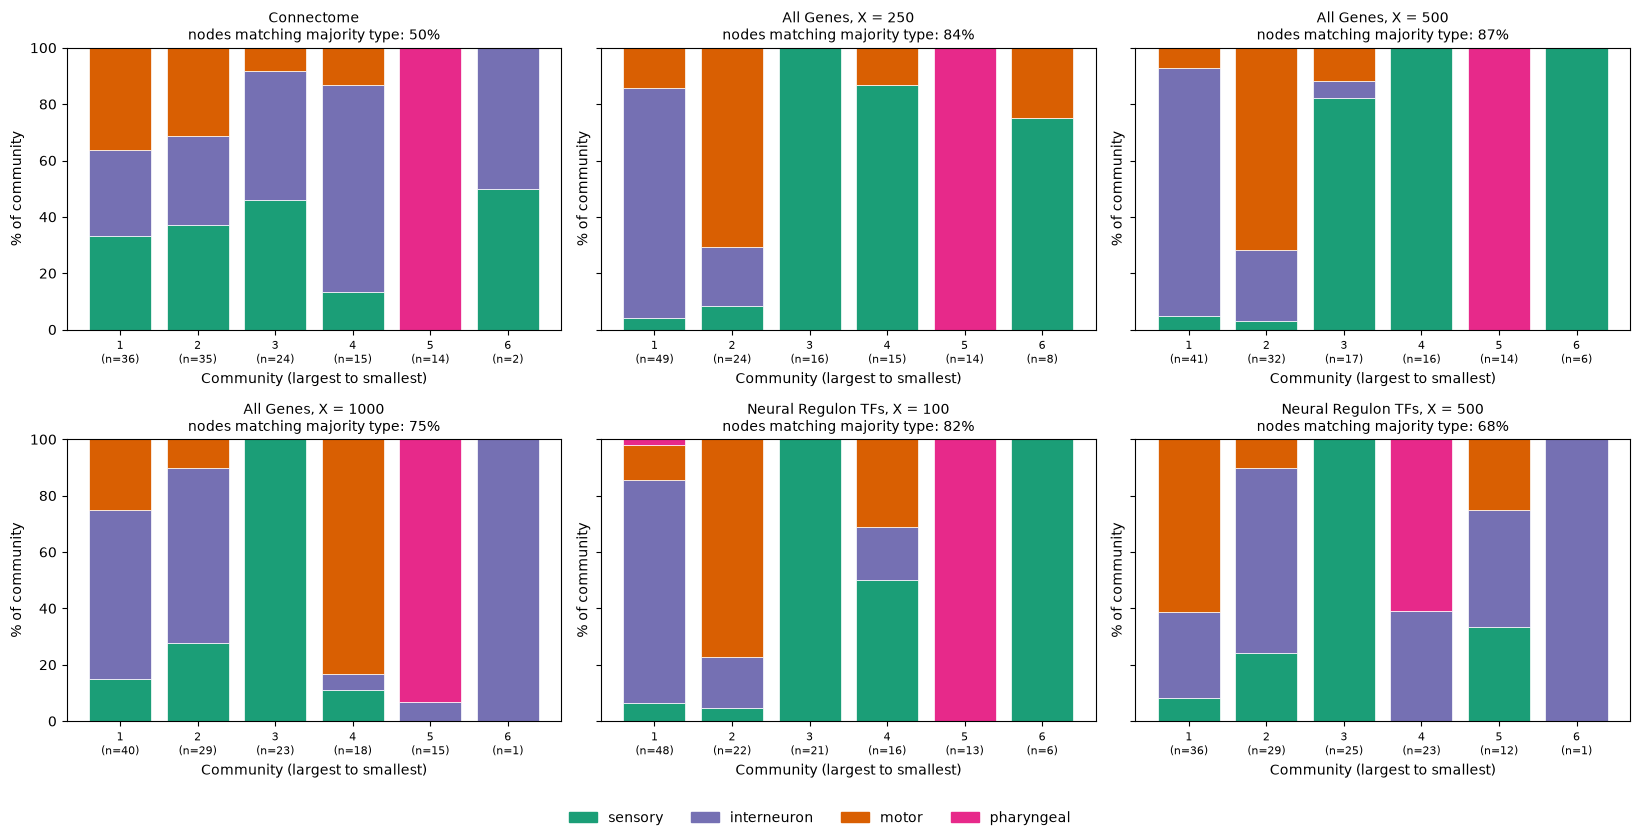

,network,n_communities,purity
0,Connectome,6,0.500
1,"All Genes, X = 250",6,0.841
2,"All Genes, X = 500",6,0.865
3,"All Genes, X = 1000",6,0.754
4,"Neural Regulon TFs, X = 100",6,0.817
5,"Neural Regulon TFs, X = 500",6,0.683


In [ ]:
# Plot # of Greedy Modularity Communities
from collections import Counter

NEURON_TYPES = ["sensory", "interneuron", "motor", "pharyngeal"]
TYPE_COLORS = {"sensory": "#1b9e77", "interneuron": "#7570b3",
               "motor": "#d95f02", "pharyngeal": "#e7298a"}


def greedy_sorted(G, seed):
    """Louvain communities, largest first."""
    comms = nx.community.greedy_modularity_communities(G, weight="weight")
    return sorted(comms, key=len, reverse=True)


def type_percent(G, comms):
    """(n_communities x 4) array: % of each community's nodes belonging to each neuron type."""
    out = []
    for c in comms:
        cnt = Counter(G.nodes[n]["type"] for n in c)
        out.append([100 * cnt[t] / len(c) for t in NEURON_TYPES])
    return np.array(out)


def purity(G, comms):
    """Fraction of all nodes that match their community's majority type."""
    hit = sum(max(Counter(G.nodes[n]["type"] for n in c).values()) for c in comms)
    return hit / sum(len(c) for c in comms)


def plot_comm(conn, nets, lfc, types, sources, Xs, n_perm, out, seed):
    # ---- connectome (null) communities, ordered by size ----
    conn_comms = greedy_sorted(conn, seed)
    k_null = len(conn_comms)

    # Per-community type counts (connectome), largest community first
    ncols = min(3, k_null)
    nrows = (k_null + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                             sharey=True, squeeze=False)
    for i, comm in enumerate(conn_comms):
        ax = axes.flat[i]
        cnt = Counter(conn.nodes[n]["type"] for n in comm)
        ax.bar(NEURON_TYPES, [cnt[t] for t in NEURON_TYPES],
               color=[TYPE_COLORS[t] for t in NEURON_TYPES])
        ax.set_title(f"Community {i + 1} (n={len(comm)})")
        ax.set_ylabel("Number of neurons")
        ax.tick_params(axis="x", labelrotation=45)
    for ax in list(axes.flat)[k_null:]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

    # ---- communities for every expression network ----
    all_comms, n_comm = {}, {}
    for source in sources:
        for k in Xs:
            if (source, k) not in nets:
                continue
            comms = louvain_sorted(nets[(source, k)][0], seed)
            all_comms[(source, k)] = comms
            n_comm[(source, k)] = len(comms)

    # Xs whose community count equals the connectome's
    matches = {s: [k for k in Xs if n_comm.get((s, k)) == k_null] for s in sources}
    print(f"Connectome: {k_null} Greedy Modularity communities")
    for s, ks in matches.items():
        print(f"  {s}: X with {k_null} communities -> {ks if ks else 'none'}")

    # ---- number of communities vs X ----
    plt.figure()
    for source in sources:
        ks = [k for k in Xs if (source, k) in n_comm]
        plt.plot(ks, [n_comm[(source, k)] for k in ks], marker="o", label=source)
        hit = matches[source]
        if hit:   # ring the matching points
            plt.scatter(hit, [k_null] * len(hit), s=140, facecolors="none",
                        edgecolors="k", zorder=3)
    plt.axhline(k_null, ls="--", color="k", label="Connectome")
    plt.xlabel("X (top DE genes per neuron)")
    plt.ylabel("Number of Greedy Modularity Communities")
    plt.legend()
    plt.show()

    # ---- % of each community by neuron type (matching Xs + connectome) ----
    panels = [("Connectome", conn, conn_comms)]
    for s, ks in matches.items():
        for k in ks:
            panels.append((f"{s}, X = {k}", nets[(s, k)][0], all_comms[(s, k)]))

    if len(panels) == 1:
        print("No expression network matches the connectome's community count.")
    pc = min(3, len(panels))
    pr = (len(panels) + pc - 1) // pc
    fig, axes = plt.subplots(pr, pc, figsize=(5.5 * pc, 4.2 * pr),
                             sharey=True, squeeze=False)
    rows = []
    for ax, (title, G, comms) in zip(axes.flat, panels):
        pct = type_percent(G, comms)
        bottom = np.zeros(len(comms))
        xs = np.arange(len(comms))
        for j, t in enumerate(NEURON_TYPES):
            ax.bar(xs, pct[:, j], bottom=bottom, color=TYPE_COLORS[t],
                   label=t, edgecolor="white", linewidth=0.5)
            bottom += pct[:, j]
        p = purity(G, comms)
        rows.append(dict(network=title, n_communities=len(comms), purity=p))
        ax.set_xticks(xs)
        ax.set_xticklabels([f"{i + 1}\n(n={len(c)})" for i, c in enumerate(comms)],
                           fontsize=8)
        ax.set_xlabel("Community (largest to smallest)")
        ax.set_ylabel("% of community")
        ax.set_title(f"{title}\nnodes matching majority type: {p:.0%}", fontsize=10)
    for ax in list(axes.flat)[len(panels):]:
        ax.set_visible(False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=TYPE_COLORS[t]) for t in NEURON_TYPES]
    fig.legend(handles, NEURON_TYPES, loc="lower center", ncol=4, frameon=False)
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()

    return matches, pd.DataFrame(rows)


matches, purity_df = plot_comm(conn, nets, lfc, types, sources, XS, N_PERM, OUT, SEED)
purity_df.round(3)

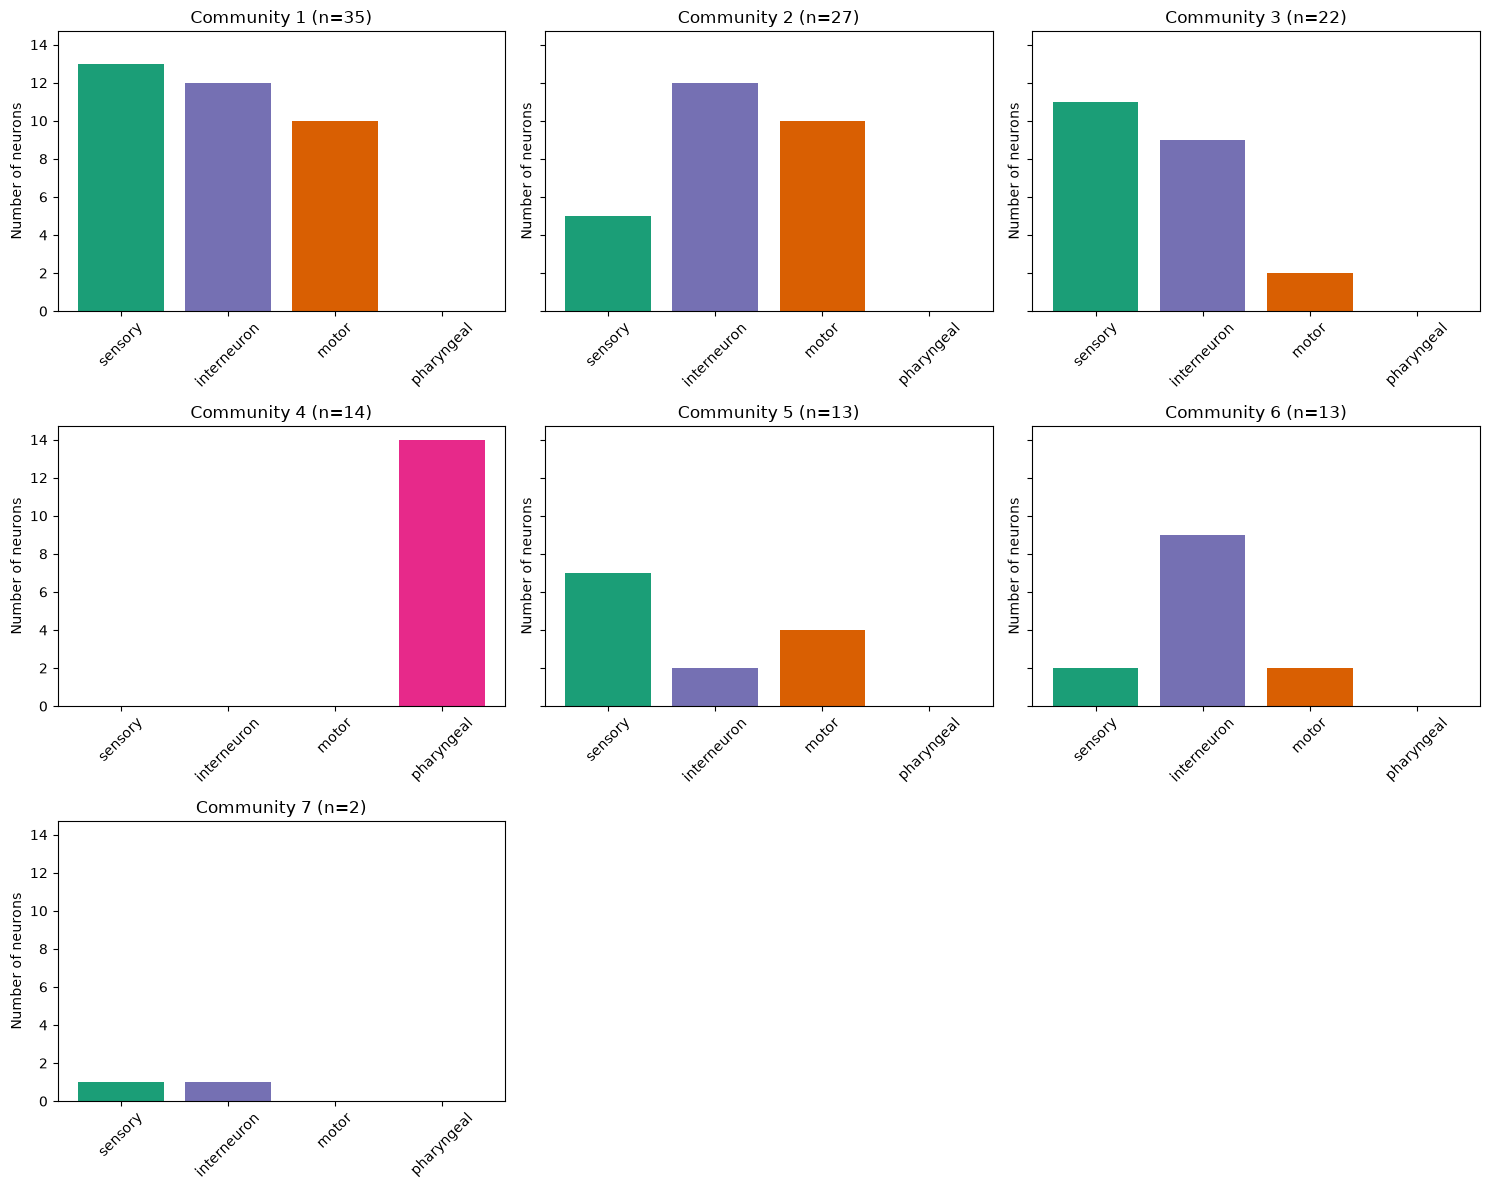

Connectome: 7 Louvain communities
  All Genes: X with 7 communities -> none
  Neural Regulon TFs: X with 7 communities -> [50]


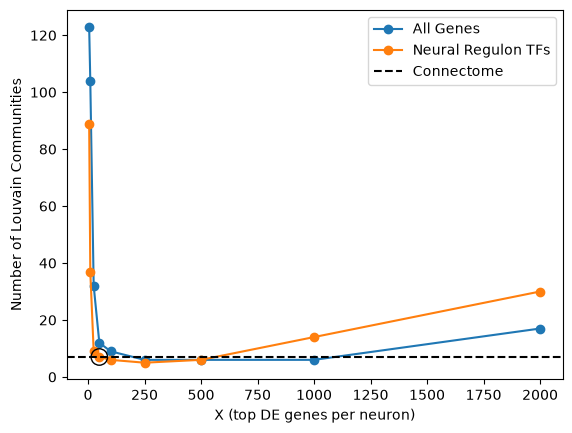

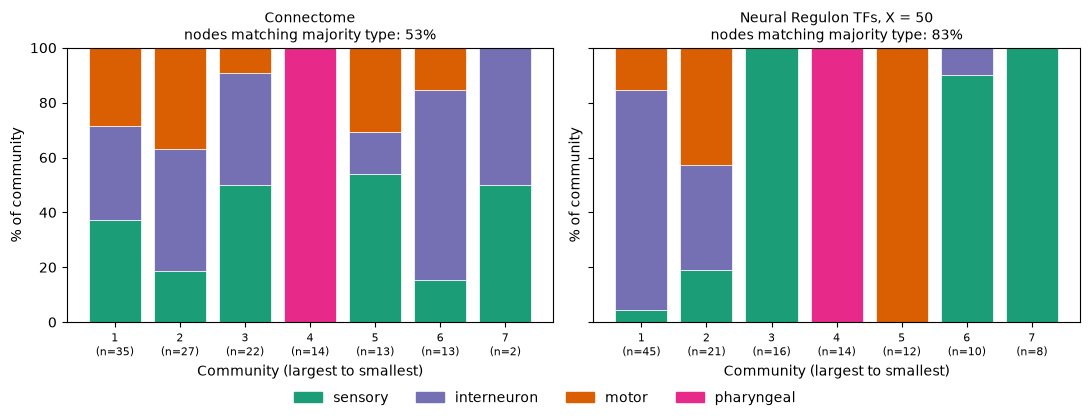

,network,n_communities,purity
0,Connectome,7,0.532
1,"Neural Regulon TFs, X = 50",7,0.825


In [ ]:
# Plot # of Louvain Modularity Communities
from collections import Counter

NEURON_TYPES = ["sensory", "interneuron", "motor", "pharyngeal"]
TYPE_COLORS = {"sensory": "#1b9e77", "interneuron": "#7570b3",
               "motor": "#d95f02", "pharyngeal": "#e7298a"}


def louvain_sorted(G, seed):
    """Louvain communities, largest first."""
    comms = nx.community.louvain_communities(G, weight="weight", seed=seed)
    return sorted(comms, key=len, reverse=True)


def type_percent(G, comms):
    """(n_communities x 4) array: % of each community's nodes belonging to each neuron type."""
    out = []
    for c in comms:
        cnt = Counter(G.nodes[n]["type"] for n in c)
        out.append([100 * cnt[t] / len(c) for t in NEURON_TYPES])
    return np.array(out)


def purity(G, comms):
    """Fraction of all nodes that match their community's majority type."""
    hit = sum(max(Counter(G.nodes[n]["type"] for n in c).values()) for c in comms)
    return hit / sum(len(c) for c in comms)


def plot_comm(conn, nets, lfc, types, sources, Xs, n_perm, out, seed):
    # ---- connectome (null) communities, ordered by size ----
    conn_comms = louvain_sorted(conn, seed)
    k_null = len(conn_comms)

    # Per-community type counts (connectome), largest community first
    ncols = min(3, k_null)
    nrows = (k_null + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                             sharey=True, squeeze=False)
    for i, comm in enumerate(conn_comms):
        ax = axes.flat[i]
        cnt = Counter(conn.nodes[n]["type"] for n in comm)
        ax.bar(NEURON_TYPES, [cnt[t] for t in NEURON_TYPES],
               color=[TYPE_COLORS[t] for t in NEURON_TYPES])
        ax.set_title(f"Community {i + 1} (n={len(comm)})")
        ax.set_ylabel("Number of neurons")
        ax.tick_params(axis="x", labelrotation=45)
    for ax in list(axes.flat)[k_null:]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

    # ---- communities for every expression network ----
    all_comms, n_comm = {}, {}
    for source in sources:
        for k in Xs:
            if (source, k) not in nets:
                continue
            comms = louvain_sorted(nets[(source, k)][0], seed)
            all_comms[(source, k)] = comms
            n_comm[(source, k)] = len(comms)

    # Xs whose community count equals the connectome's
    matches = {s: [k for k in Xs if n_comm.get((s, k)) == k_null] for s in sources}
    print(f"Connectome: {k_null} Louvain communities")
    for s, ks in matches.items():
        print(f"  {s}: X with {k_null} communities -> {ks if ks else 'none'}")

    # ---- number of communities vs X ----
    plt.figure()
    for source in sources:
        ks = [k for k in Xs if (source, k) in n_comm]
        plt.plot(ks, [n_comm[(source, k)] for k in ks], marker="o", label=source)
        hit = matches[source]
        if hit:   # ring the matching points
            plt.scatter(hit, [k_null] * len(hit), s=140, facecolors="none",
                        edgecolors="k", zorder=3)
    plt.axhline(k_null, ls="--", color="k", label="Connectome")
    plt.xlabel("X (top DE genes per neuron)")
    plt.ylabel("Number of Louvain Communities")
    plt.legend()
    plt.show()

    # ---- % of each community by neuron type (matching Xs + connectome) ----
    panels = [("Connectome", conn, conn_comms)]
    for s, ks in matches.items():
        for k in ks:
            panels.append((f"{s}, X = {k}", nets[(s, k)][0], all_comms[(s, k)]))

    if len(panels) == 1:
        print("No expression network matches the connectome's community count.")
    pc = min(3, len(panels))
    pr = (len(panels) + pc - 1) // pc
    fig, axes = plt.subplots(pr, pc, figsize=(5.5 * pc, 4.2 * pr),
                             sharey=True, squeeze=False)
    rows = []
    for ax, (title, G, comms) in zip(axes.flat, panels):
        pct = type_percent(G, comms)
        bottom = np.zeros(len(comms))
        xs = np.arange(len(comms))
        for j, t in enumerate(NEURON_TYPES):
            ax.bar(xs, pct[:, j], bottom=bottom, color=TYPE_COLORS[t],
                   label=t, edgecolor="white", linewidth=0.5)
            bottom += pct[:, j]
        p = purity(G, comms)
        rows.append(dict(network=title, n_communities=len(comms), purity=p))
        ax.set_xticks(xs)
        ax.set_xticklabels([f"{i + 1}\n(n={len(c)})" for i, c in enumerate(comms)],
                           fontsize=8)
        ax.set_xlabel("Community (largest to smallest)")
        ax.set_ylabel("% of community")
        ax.set_title(f"{title}\nnodes matching majority type: {p:.0%}", fontsize=10)
    for ax in list(axes.flat)[len(panels):]:
        ax.set_visible(False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=TYPE_COLORS[t]) for t in NEURON_TYPES]
    fig.legend(handles, NEURON_TYPES, loc="lower center", ncol=4, frameon=False)
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()

    return matches, pd.DataFrame(rows)


matches, purity_df = plot_comm(conn, nets, lfc, types, sources, XS, N_PERM, OUT, SEED)
purity_df.round(3)

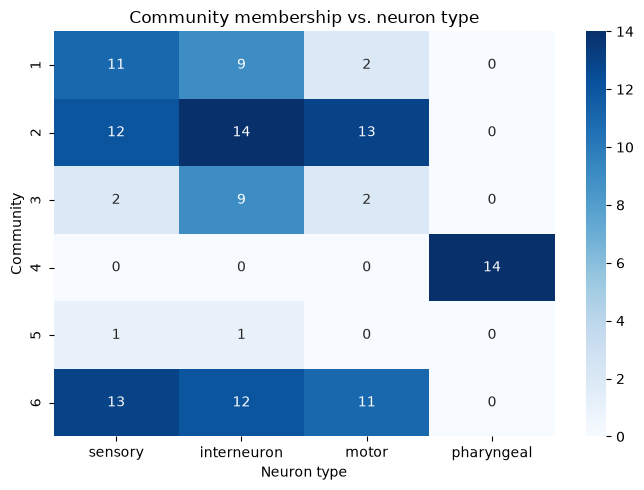

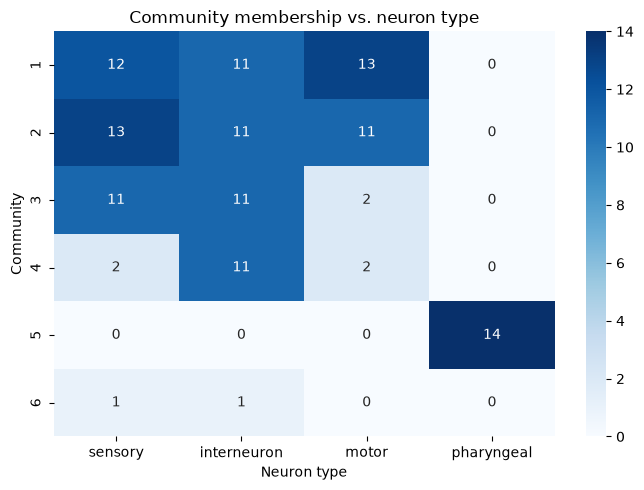

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Pair each neuron's inferred community with its annotation

communities = nx.community.louvain_communities(conn,weight='weight')

df = pd.DataFrame([
    {"Community": i + 1, "Neuron type": conn.nodes[node]["type"]}
    for i, community in enumerate(communities)
    for node in community
])

matrix = pd.crosstab(df["Community"], df["Neuron type"])
matrix = matrix.reindex(
    columns=["sensory", "interneuron", "motor", "pharyngeal"],
    fill_value=0
)

plt.figure(figsize=(7, 5))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Community membership vs. neuron type")
plt.tight_layout()
plt.show()

g_communities = nx.community.greedy_modularity_communities(conn,weight='weight')

df = pd.DataFrame([
    {"Community": i + 1, "Neuron type": conn.nodes[node]["type"]}
    for i, community in enumerate(g_communities)
    for node in community
])

matrix = pd.crosstab(df["Community"], df["Neuron type"])
matrix = matrix.reindex(
    columns=["sensory", "interneuron", "motor", "pharyngeal"],
    fill_value=0
)

plt.figure(figsize=(7, 5))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Community membership vs. neuron type")
plt.tight_layout()
plt.show()

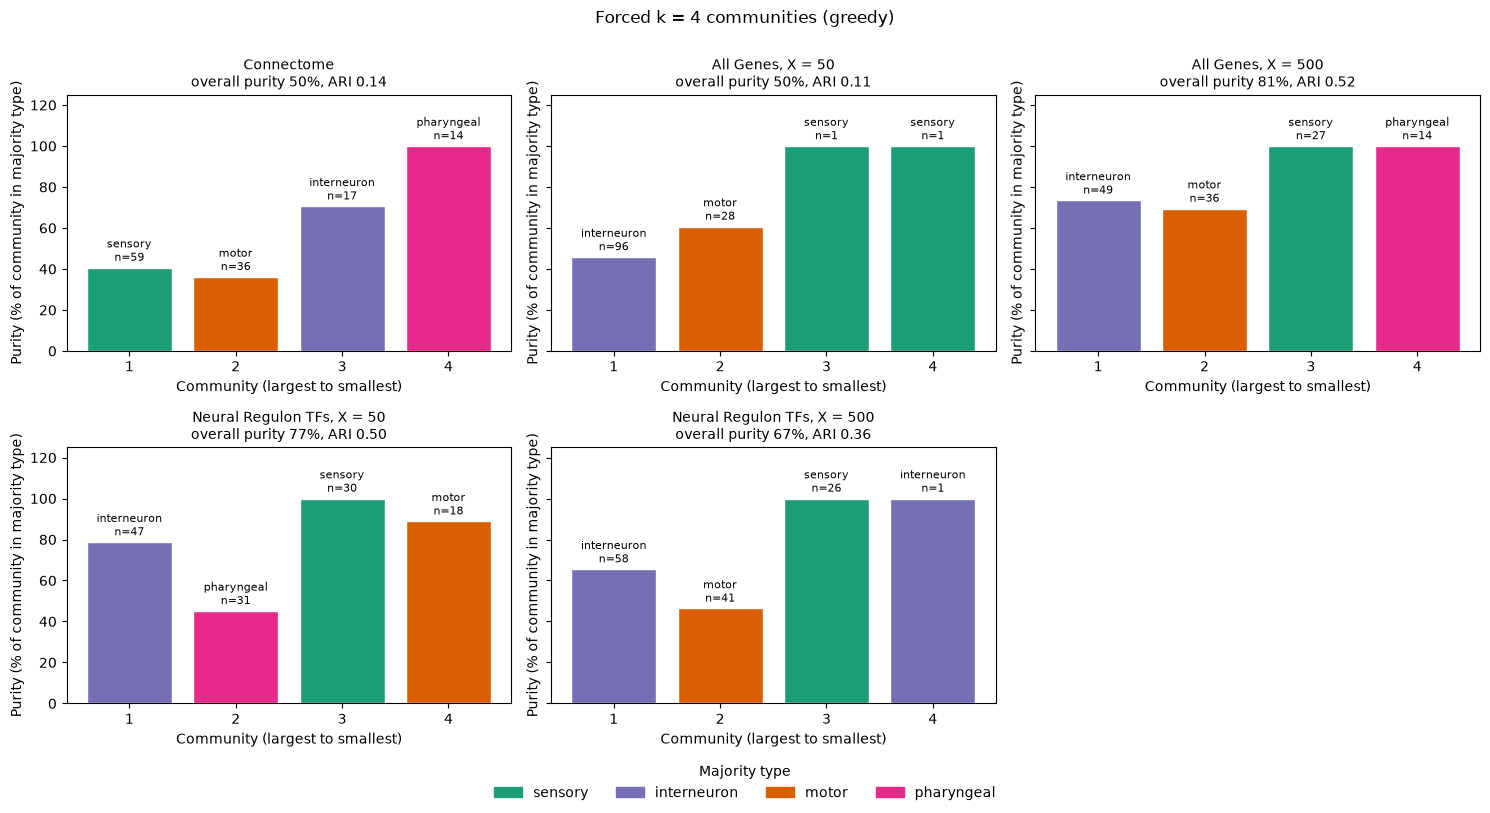

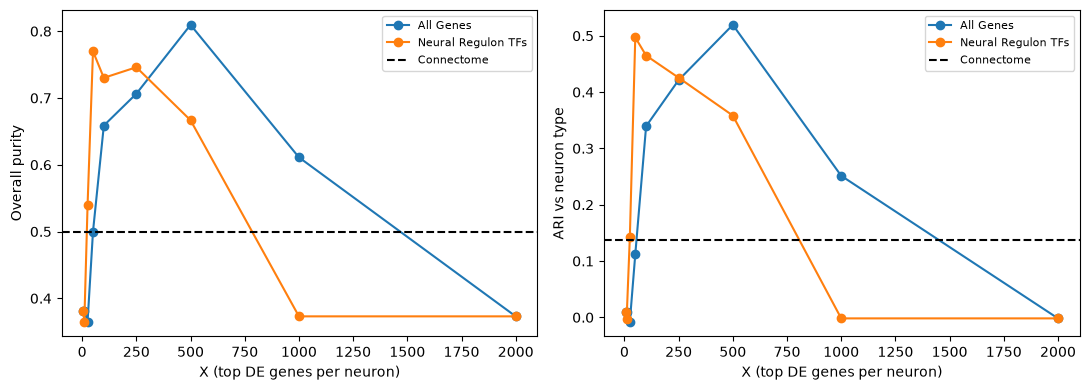

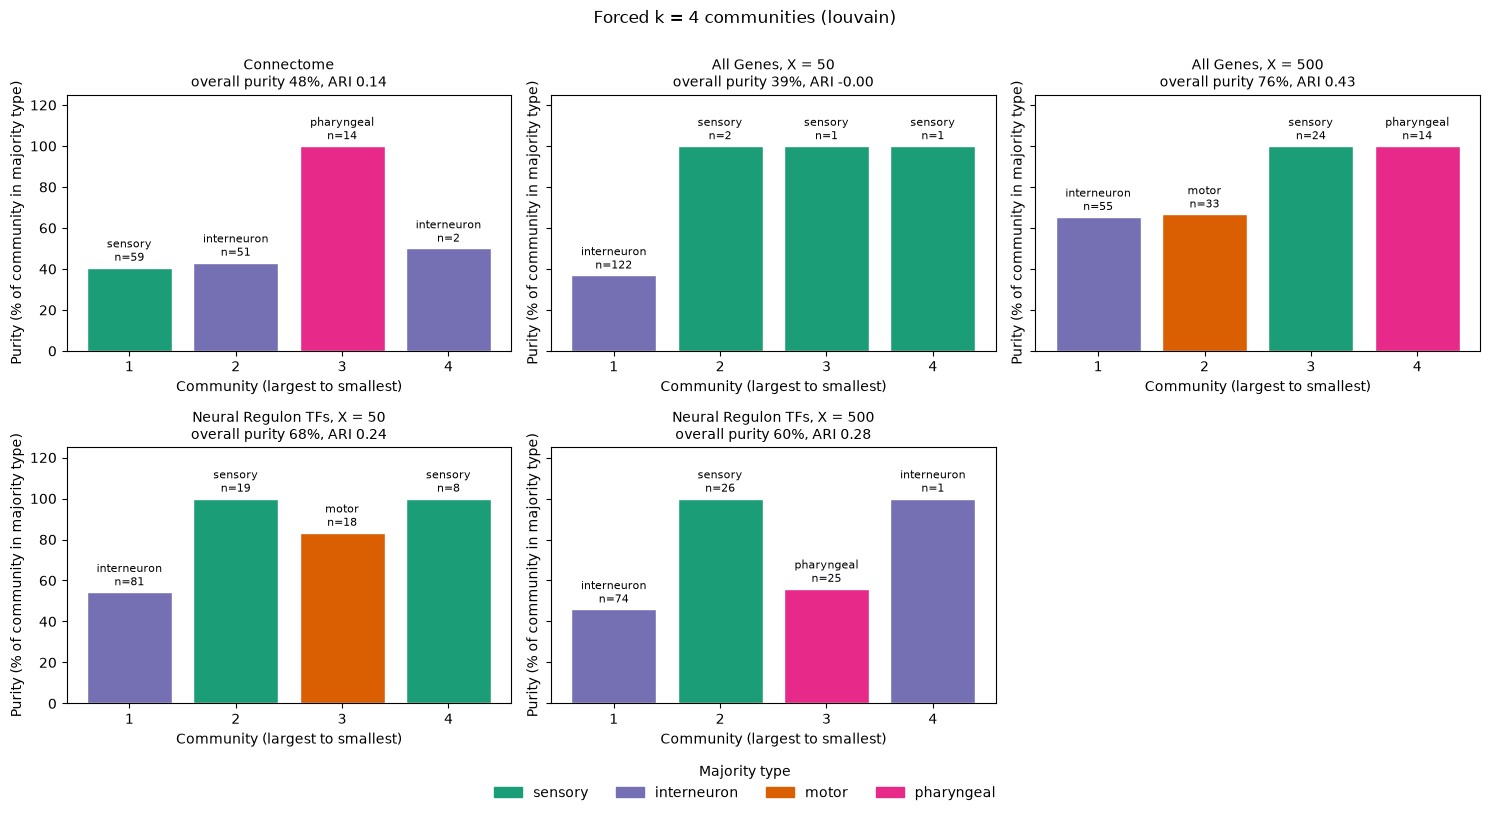

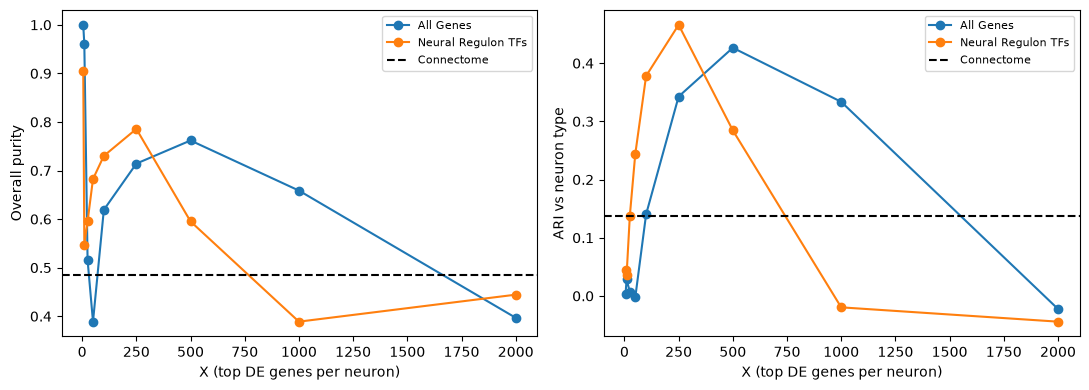

,network,purity,ARI,NMI
0,Connectome,0.484,0.137,0.310
1,"All Genes, X = 50",0.389,-0.003,0.052
2,"All Genes, X = 500",0.762,0.427,0.562
3,"Neural Regulon TFs, X = 50",0.683,0.244,0.400
4,"Neural Regulon TFs, X = 500",0.595,0.285,0.469


In [ ]:
# Force k = 4 communities and chart purity per community
from collections import Counter
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

NEURON_TYPES = ["sensory", "interneuron", "motor", "pharyngeal"]
TYPE_COLORS = {"sensory": "#1b9e77", "interneuron": "#7570b3",
               "motor": "#d95f02", "pharyngeal": "#e7298a"}


def force_k_communities(G, k=4, method="spectral", seed=0):
    """Partition G into exactly k communities, largest first.
    method: 'spectral'  - spectral clustering on the weighted adjacency matrix
            'greedy'    - greedy modularity, merging stopped at k communities
            'louvain'   - Louvain, resolution tuned until it returns k communities
    """
    nodes = list(G.nodes)
    if method == "spectral":
        A = nx.to_numpy_array(G, nodelist=nodes, weight="weight")
        labels = SpectralClustering(n_clusters=k, affinity="precomputed",
                                    random_state=seed).fit_predict(A)
        comms = [{nodes[i] for i in np.where(labels == c)[0]} for c in range(k)]
    elif method == "greedy":
        comms = nx.community.greedy_modularity_communities(
            G, weight="weight", cutoff=k, best_n=k)
    elif method == "louvain":
        best, best_q, closest = None, -np.inf, None
        for r in np.geomspace(0.02, 5, 80):
            c = nx.community.louvain_communities(G, weight="weight",
                                                 resolution=r, seed=seed)
            if closest is None or abs(len(c) - k) < abs(len(closest) - k):
                closest = c
            if len(c) == k:
                q = nx.community.modularity(G, c, weight="weight")
                if q > best_q:
                    best, best_q = c, q
        comms = best if best is not None else closest
        if best is None:
            print(f"  warning: Louvain never returned {k} communities "
                  f"(closest: {len(closest)})")
    else:
        raise ValueError(method)
    return sorted([set(c) for c in comms if len(c)], key=len, reverse=True)


def community_purity(G, comms):
    """Per-community table + overall purity / ARI / NMI against neuron type."""
    rows = []
    for i, c in enumerate(comms):
        cnt = Counter(G.nodes[n]["type"] for n in c)
        maj, m = cnt.most_common(1)[0]
        rows.append(dict(community=i + 1, size=len(c), majority=maj, purity=m / len(c)))
    tab = pd.DataFrame(rows)
    nodes = [n for c in comms for n in c]
    true = [G.nodes[n]["type"] for n in nodes]
    pred = [i for i, c in enumerate(comms) for _ in c]
    overall = dict(purity=(tab.purity * tab["size"]).sum() / tab["size"].sum(),
                   ARI=adjusted_rand_score(true, pred),
                   NMI=normalized_mutual_info_score(true, pred))
    return tab, overall


def plot_forced_purity(conn, nets, sources, Xs, X_show, k=4,
                       method="spectral", seed=0):
    # ---- panels: connectome + each source at the chosen X values ----
    panels = [("Connectome", conn)]
    for s in sources:
        for X in X_show:
            if (s, X) in nets:
                panels.append((f"{s}, X = {X}", nets[(s, X)][0]))

    pc = min(3, len(panels))
    pr = (len(panels) + pc - 1) // pc
    fig, axes = plt.subplots(pr, pc, figsize=(5 * pc, 4 * pr),
                             sharey=True, squeeze=False)
    summary = []
    for ax, (title, G) in zip(axes.flat, panels):
        comms = force_k_communities(G, k, method, seed)
        tab, overall = community_purity(G, comms)
        ax.bar(range(len(tab)), tab.purity * 100,
               color=[TYPE_COLORS[m] for m in tab.majority],
               edgecolor="white")
        for i, r in tab.iterrows():
            ax.text(i, r.purity * 100 + 1.5, f"{r.majority}\nn={r['size']}",
                    ha="center", va="bottom", fontsize=8)
        ax.set_xticks(range(len(tab)))
        ax.set_xticklabels([f"{c}" for c in tab.community])
        ax.set_xlabel("Community (largest to smallest)")
        ax.set_ylabel("Purity (% of community in majority type)")
        ax.set_ylim(0, 125)
        ax.set_title(f"{title}\noverall purity {overall['purity']:.0%}, "
                     f"ARI {overall['ARI']:.2f}", fontsize=10)
        summary.append(dict(network=title, **overall))
    for ax in list(axes.flat)[len(panels):]:
        ax.set_visible(False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=TYPE_COLORS[t]) for t in NEURON_TYPES]
    fig.legend(handles, NEURON_TYPES, title="Majority type", loc="lower center",
               ncol=4, frameon=False)
    fig.suptitle(f"Forced k = {k} communities ({method})", y=1.0)
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

    # ---- ARI and overall purity vs X ----
    _, base = community_purity(conn, force_k_communities(conn, k, method, seed))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axes, ["purity", "ARI"]):
        for s in sources:
            ks = [X for X in Xs if (s, X) in nets]
            vals = [community_purity(nets[(s, X)][0],
                    force_k_communities(nets[(s, X)][0], k, method, seed))[1][metric]
                    for X in ks]
            ax.plot(ks, vals, marker="o", label=s)
        ax.axhline(base[metric], ls="--", color="k", label="Connectome")
        ax.set_xlabel("X (top DE genes per neuron)")
        ax.set_ylabel("Overall purity" if metric == "purity" else "ARI vs neuron type")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(summary)


forced = plot_forced_purity(conn, nets, sources, XS, X_show=[50, 500],
                            k=4, method="greedy", seed=SEED)

forced = plot_forced_purity(conn, nets, sources, XS, X_show=[50, 500],
                            k=4, method="louvain", seed=SEED)